# Explanation demo

I check a few explanations, then compare the strongest feature changes with random ones. The language model only rewrites facts from the scorer.

In [1]:
from pathlib import Path
import json
import os
import sys
import time
from collections import Counter

# Keep imports working when nbconvert runs from notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from explain import MODEL_ID, NAMES, UNITS, _logit, _neutralize, _reference, explain
from model import Scorer
from preprocess import advanced_features

scorer = Scorer('advanced')
threshold = scorer.threshold
test = pd.read_csv(ROOT / 'data/test.csv')
predictions = pd.read_csv(ROOT / 'predictions.csv')
scored = test.merge(predictions, on='url', validate='one_to_one')
scored['predicted'] = (scored.probability >= threshold).astype(int)
scored.head()

,url,label,probability,predicted
0,http://gabung-gruppwhattsapp18.port25.biz/,1,0.999876,1
1,http://www.sparknotes.com/biology/molecular/dn...,0,0.011925,0
2,http://shadetreetechnology.com/V4/validation/8...,1,0.999906,1
3,https://www.booooooom.com/,0,0.002308,0
4,http://www.studytonight.com/computer-networks/...,0,0.000334,0


In [2]:
llm_model_comparison = json.loads(
    (ROOT / 'reports/explain_eval.json').read_text()
).get('llm_model_comparison', {})

## Examples

I use the requested PayPal URL and small, seeded samples from each test-set outcome. Labels below are the test labels; verdicts are the model predictions.

In [3]:
example_groups = [
    ('true positive', (scored.label == 1) & (scored.predicted == 1), 3),
    ('false positive', (scored.label == 0) & (scored.predicted == 1), 2),
    ('false negative', (scored.label == 1) & (scored.predicted == 0), 2),
    ('true negative', (scored.label == 0) & (scored.predicted == 0), 2),
]
example_inputs = [('PayPal example', 'https://www.PayPal-secure.login.tk/webscr?cmd=x', None, None)]
for group, mask, count in example_groups:
    sample = scored.loc[mask].sample(n=count, random_state=0)
    example_inputs.extend((group, row.url, int(row.label), float(row.probability))
                          for row in sample.itertuples())

example_cache, examples = {}, []
for group, url, true_label, fixed_score in example_inputs:
    started = time.perf_counter()
    result = explain(url, scorer=scorer, use_llm=True)
    elapsed = time.perf_counter() - started
    score = result['probability'] if fixed_score is None else fixed_score
    example_cache[url] = {'result': result, 'seconds': elapsed}
    examples.append({'sample': group, 'url': url, 'label': true_label,
                     'verdict': result['label'], 'score': score,
                     'text': result['text'], 'facts': result['facts'],
                     'generated_by': result['generated_by'],
                     'reasons': result['reasons']})
example_table = pd.DataFrame(examples)
display(example_table[['sample', 'url', 'label', 'verdict', 'score', 'text', 'facts', 'generated_by']])

/home/ubuntu/v6/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:567: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/home/ubuntu/v6/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:572: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/home/ubuntu/v6/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:589: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


,sample,url,label,verdict,score,text,facts,generated_by
0,PayPal example,https://www.PayPal-secure.login.tk/webscr?cmd=x,NaN,phishing,1.000000,The detector scored PayPal Secure login page a...,This URL is flagged as phishing with a very hi...,Qwen/Qwen2.5-0.5B-Instruct
1,true positive,http://104.237.152.236/nh6pzb,1.0,phishing,0.999749,The detector scored 1.00 because the URL conta...,This URL is flagged as phishing with a very hi...,Qwen/Qwen2.5-0.5B-Instruct
2,true positive,http://mail.openatelier.nl/~u43730p39181/pki-v...,1.0,phishing,0.996736,This URL is flagged as phishing with a very hi...,This URL is flagged as phishing with a very hi...,template
3,true positive,https://three-gb.com/banks/online.tsb.co.uk/,1.0,phishing,0.999414,This URL is flagged as phishing with a very hi...,This URL is flagged as phishing with a very hi...,template
4,false positive,http://back.dog/auth/login,0.0,phishing,0.999788,This URL is flagged as phishing with a very hi...,This URL is flagged as phishing with a very hi...,template
5,false positive,http://html.freebuddymovies.com/5/79/pics/5593...,0.0,phishing,0.987599,The detector scored 0.99 because the presence ...,"This URL is flagged as phishing, but only just...",Qwen/Qwen2.5-0.5B-Instruct
6,false negative,https://ocurenc.com,1.0,clean,0.902286,"This URL is treated as clean, but it is a bord...","This URL is treated as clean, but it is a bord...",template
7,false negative,http://us.megamilly.com/index/log/claim/claims...,1.0,clean,0.661839,"This URL is treated as clean, but it is a bord...","This URL is treated as clean, but it is a bord...",template
8,true negative,https://tabs.ultimate-guitar.com/0-9/5_seconds...,0.0,clean,0.031300,This URL looks clean: its score of 0.03 is far...,This URL looks clean: its score of 0.03 is far...,template
9,true negative,https://www.holikaholika.ee/en/,0.0,clean,0.059588,This URL looks clean: its score of 0.06 is far...,This URL looks clean: its score of 0.06 is far...,template


## Faithfulness check without the language model

I neutralise the three reported units and compare their logit drop with three other units sampled using a fixed random seed. A larger drop means the selected units changed the score more in this occlusion test.

n                            200.000000
median_drop_top3               6.036971
median_drop_rand3              0.001957
share_top3_exceeds_random      1.000000
share_top3_flips_to_clean      0.825000
dtype: float64

,a,b,count
0,path/query character patterns,words in the URL,60
1,digits in the host,words in the URL,25
2,suspicious words,words in the URL,21
3,host character patterns,words in the URL,13
4,path/query character patterns,suspicious words,12


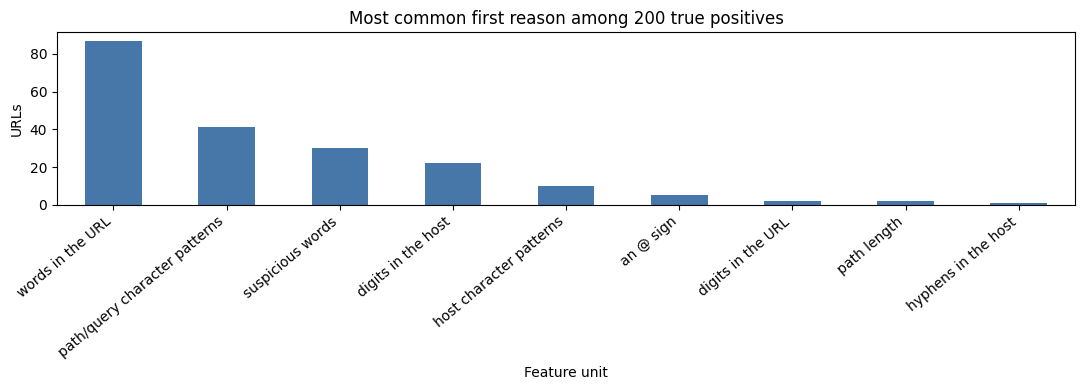

In [4]:
true_positives = scored.loc[(scored.label == 1) & (scored.predicted == 1)]
faithfulness_sample = true_positives.sample(n=200, random_state=0).reset_index(drop=True)
rng = np.random.default_rng(0)
reference = _reference()
neutral_rows, faithfulness_rows = [], []
name_to_unit = {name: key for key, name in NAMES.items()}
for row in faithfulness_sample.itertuples():
    result = explain(row.url, scorer=scorer, use_llm=False)
    top3 = [name_to_unit[item['name']] for item in result['reasons']]
    other_units = [key for key in UNITS if key not in top3]
    random3 = rng.choice(other_units, size=3, replace=False).tolist()
    x = advanced_features([row.url]).toarray()
    neutral_rows.extend((_neutralize(x, top3, reference), _neutralize(x, random3, reference)))
    faithfulness_rows.append({'url': row.url, 'score': float(row.probability),
                               'reason1': result['reasons'][0]['name'],
                               'combination': result['combination']})

# Score the paired occlusions together so each URL uses the same scorer path.
without_scores = scorer.score_matrix(np.vstack(neutral_rows))
drop_top3, drop_rand3 = [], []
for i, row in enumerate(faithfulness_rows):
    full = float(_logit(row['score']))
    drop_top3.append(full - float(_logit(without_scores[2 * i])))
    drop_rand3.append(full - float(_logit(without_scores[2 * i + 1])))
faithfulness = {
    'n': len(faithfulness_rows),
    'median_drop_top3': float(np.median(drop_top3)),
    'median_drop_rand3': float(np.median(drop_rand3)),
    'share_top3_exceeds_random': float(np.mean(np.asarray(drop_top3) > np.asarray(drop_rand3))),
    'share_top3_flips_to_clean': float(np.mean(without_scores[::2] < threshold)),
}
reason_counts = Counter(row['reason1'] for row in faithfulness_rows)
combination_counts = Counter(tuple(sorted((row['combination']['a'], row['combination']['b'])))
                             for row in faithfulness_rows)
faithfulness['reason1_counts'] = dict(reason_counts.most_common())
faithfulness['common_combinations'] = [
    {'a': pair[0], 'b': pair[1], 'count': count}
    for pair, count in combination_counts.most_common(5)
]
display(pd.Series({key: value for key, value in faithfulness.items()
                   if key not in ('reason1_counts', 'common_combinations')}))
display(pd.DataFrame(faithfulness['common_combinations']))
fig, ax = plt.subplots(figsize=(11, 4))
pd.Series(reason_counts).sort_values(ascending=False).plot.bar(ax=ax, color='#4776a8')
ax.set(title='Most common first reason among 200 true positives', ylabel='URLs', xlabel='Feature unit')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

## Language-model checks

I time the first 50 URLs from the same phishing sample with and without wording. A template result means the chosen model output failed a guard, including the reason-1 mention check, or was unavailable. The reason-1 mention check is enforced by the guard, so passing model texts always mention the top reason.

In [5]:
llm_rows, no_llm_seconds, llm_samples = [], [], []
for row in faithfulness_sample.head(50).itertuples():
    started = time.perf_counter()
    no_llm = explain(row.url, scorer=scorer, use_llm=False)
    no_llm_seconds.append(time.perf_counter() - started)
    cached = example_cache.get(row.url)
    if cached:
        result, elapsed = cached['result'], cached['seconds']
    else:
        started = time.perf_counter()
        result = explain(row.url, scorer=scorer, use_llm=True)
        elapsed = time.perf_counter() - started
    reason1 = no_llm['reasons'][0]['name']
    first_words = ' '.join(reason1.split()[:2]).casefold()
    mentions = first_words in result['text'].casefold()
    llm_rows.append({'url': row.url, 'seconds': elapsed,
                     'generated_by': result['generated_by'],
                     'mentions_reason1': mentions})
    llm_samples.append({'url': row.url, 'text': result['text'],
                        'facts': result['facts'],
                        'generated_by': result['generated_by']})
model_rows = [r for r in llm_rows if r['generated_by'] == MODEL_ID]
llm_checks = {
    'n': len(llm_rows),
    'n_llm_texts': len(model_rows),
    'template_guard_fallback_share': float(np.mean(
        [r['generated_by'] == 'template' for r in llm_rows])),
    'mean_seconds_with_llm': float(np.mean([r['seconds'] for r in llm_rows])),
    'mean_seconds_without_llm': float(np.mean(no_llm_seconds)),
    'share_llm_texts_mention_reason1': float(np.mean(
        [r['mentions_reason1'] for r in model_rows])),
}
display(pd.Series(llm_checks))
evaluation = {
    'examples': examples,
    'faithfulness': faithfulness,
    'llm_checks': llm_checks,
    'llm_model_comparison': llm_model_comparison,
}
(ROOT / 'reports/explain_llm_samples.json').write_text(json.dumps(llm_samples, indent=2))
(ROOT / 'reports/explain_eval.json').write_text(json.dumps(evaluation, indent=2))
print('Saved reports/explain_eval.json and reports/explain_llm_samples.json')

/home/ubuntu/v6/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:567: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/home/ubuntu/v6/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:572: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/home/ubuntu/v6/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:589: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


n                                  50.000000
n_llm_texts                        18.000000
template_guard_fallback_share       0.640000
mean_seconds_with_llm               3.679412
mean_seconds_without_llm            0.022459
share_llm_texts_mention_reason1     1.000000
dtype: float64

Saved reports/explain_eval.json and reports/explain_llm_samples.json
